In [103]:
import pandas as pd
import matplotlib.pyplot as plt

In [104]:
tumor = "t25"
tumor_variants = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_variant_counts.txt", sep = "\t")

In [105]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")

In [106]:
normal_info = A_df[["population", "normal_population"]].drop_duplicates()
normal_A = normal_info[normal_info["normal_population"] == True]["population"].values[0]

In [107]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }

A111
A112
A1211
A1212
A122
A211
A212
A221111
A221112
A221121
A221122
A2212
A222


In [108]:
tumor_variants = tumor_variants[tumor_variants["alt_count"]>0]

In [109]:
len(tumor_variants)

3240

In [110]:
tumor_variants["chrom"].unique()

array(['chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr1', 'chr21',
       'chr15', 'chr16', 'chr17', 'chr7', 'chr18', 'chr19', 'chr3',
       'chr2', 'chr20', 'chr22', 'chr4', 'chr5', 'chr6', 'chr8', 'chr9',
       'chrM', 'chrX', 'chrY'], dtype=object)

In [111]:
chrom_set = ["chr"+str(i) for i in range(1,23)] + ["chrX"]

In [112]:
pop_var_dict = {}
tot_var_dict = {}
for pop in A_dict.keys():
    pop_var_dict[pop] = {}
    tot_var_dict[pop] = 0
for ch in chrom_set:
    ch_var = tumor_variants[tumor_variants['chrom'] == ch]
    for pop in A_dict.keys():
        pop_cells = A_dict[pop]['cells']
        pop_ch_var = ch_var[ch_var['cell_id'].isin(pop_cells)]
        cells_with_var = pop_ch_var['cell_id'].unique()
        pop_var = pop_ch_var["pos"].unique()
        pop_var_dict[pop][ch] = pop_var
        tot_var_dict[pop] += len(pop_var)
    #print(pop,len(cells_with_var), len(cells_with_var)/len(pop_cells))

In [113]:
# variants per cell in each cluster
for pop in tot_var_dict:
    print(pop, tot_var_dict[pop]/len(A_dict[pop]['cells']))

A111 0.391304347826087
A112 0.6790123456790124
A1211 0.5625
A1212 1.1282051282051282
A122 0.2671102661596958
A211 2.88
A212 2.3125
A221111 3.090909090909091
A221112 2.25
A221121 2.4871794871794872
A221122 2.107142857142857
A2212 2.050632911392405
A222 2.9596774193548385


In [114]:
#pop_var_dict

In [115]:
tumor_variants = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_pseudo_variants.txt", sep = "\t")

In [116]:
tumor_variants = tumor_variants[tumor_variants["alt_count"]>0]

In [117]:
len(tumor_variants)

61

In [118]:
pop_var_dict = {}
tot_var_dict = {}
for pop in A_dict.keys():
    pop_var_dict[pop] = {}
    tot_var_dict[pop] = 0
for ch in chrom_set:
    ch_var = tumor_variants[tumor_variants['chrom'] == ch]
    for pop in A_dict.keys():
        pop_cells = A_dict[pop]['cells']
        pop_ch_var = ch_var[ch_var['cell_id'].isin(pop_cells)]
        cells_with_var = pop_ch_var['cell_id'].unique()
        pop_var = pop_ch_var["pos"].unique()
        pop_var_dict[pop][ch] = pop_var
        tot_var_dict[pop] += len(pop_var)
    #print(pop,len(cells_with_var), len(cells_with_var)/len(pop_cells))

In [119]:
# pseudo variants per cell in each cluster
for pop in tot_var_dict:
    print(pop, tot_var_dict[pop]/len(A_dict[pop]['cells']))

A111 0.043478260869565216
A112 0.012345679012345678
A1211 0.0
A1212 0.05128205128205128
A122 0.017110266159695818
A211 0.04
A212 0.020833333333333332
A221111 0.0
A221112 0.0625
A221121 0.05128205128205128
A221122 0.07142857142857142
A2212 0.02109704641350211
A222 0.016129032258064516


In [120]:
# First, load the real variants
tumor_variants_real = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_variant_counts.txt", sep="\t")
#tumor_variants_real = tumor_variants_real[tumor_variants_real["alt_count"] > 0]

# Then load pseudo variants
tumor_variants_pseudo = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_pseudo_variants.txt", sep="\t")
#tumor_variants_pseudo = tumor_variants_pseudo[tumor_variants_pseudo["alt_count"] > 0]


In [121]:
tumor_variants_real.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
0,chr10,530689,TTGGGAGATAGAACAAT,0,0,0,2,2,0,2
1,chr10,530689,GCATCGTATTCTAGAGA,0,0,0,1,1,0,1
2,chr10,1633345,GGGTCTGGCTATTCTCG,0,1,0,0,1,0,1
3,chr10,2701946,CCAGCTTTCCCAGATCG,0,0,4,0,4,0,4
4,chr10,2701946,ACGTCCAAGGCCTGTGG,0,0,1,0,1,0,1


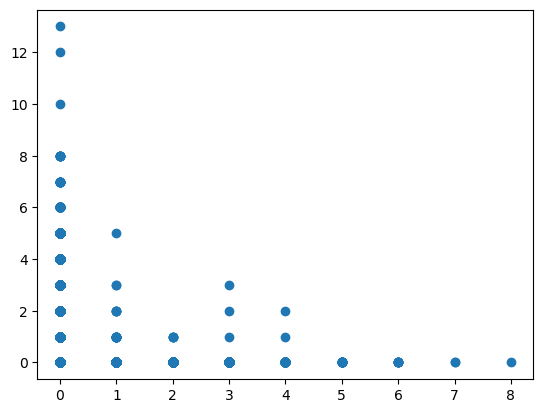

In [122]:
plt.plot(tumor_variants_real['alt_count'], tumor_variants_real['ref_count'], 'o')

In [123]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real[tumor_variants_real['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [124]:
# Create the summary table
variant_summary = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [125]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants
0,A111,115,1284,56,43,1245,5,5
1,A112,81,1038,61,34,1057,2,2
2,A1211,64,747,40,21,787,0,0
3,A1212,39,509,46,21,525,2,2
4,A122 (normal),1052,10936,437,331,10934,19,18
5,A211,50,766,153,45,766,2,2
6,A212,48,559,117,42,557,1,1
7,A221111,44,628,142,41,641,0,0
8,A221112,48,874,114,40,880,4,4
9,A221121,39,540,103,31,583,2,2


In [126]:
variant_summary["variant_frequency"] = variant_summary["variant_observed"]/variant_summary["opportunities_for_variants"]
variant_summary["pseudo_frequency"] = variant_summary["pseudo_variant_observed"]/variant_summary["opportunities_for_pseudo"]
variant_summary["variant_per_cell"] = variant_summary["variant_observed"]/variant_summary["Num_Cells"]
variant_summary["pseudo_per_cell"] = variant_summary["pseudo_variant_observed"]/variant_summary["Num_Cells"]


In [127]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A111,115,1284,56,43,1245,5,5,0.043614,0.004016,0.486957,0.043478
1,A112,81,1038,61,34,1057,2,2,0.058767,0.001892,0.753086,0.024691
2,A1211,64,747,40,21,787,0,0,0.053548,0.000000,0.625000,0.000000
3,A1212,39,509,46,21,525,2,2,0.090373,0.003810,1.179487,0.051282
4,A122 (normal),1052,10936,437,331,10934,19,18,0.039960,0.001738,0.415399,0.018061
5,A211,50,766,153,45,766,2,2,0.199739,0.002611,3.060000,0.040000
6,A212,48,559,117,42,557,1,1,0.209302,0.001795,2.437500,0.020833
7,A221111,44,628,142,41,641,0,0,0.226115,0.000000,3.227273,0.000000
8,A221112,48,874,114,40,880,4,4,0.130435,0.004545,2.375000,0.083333
9,A221121,39,540,103,31,583,2,2,0.190741,0.003431,2.641026,0.051282


In [128]:
tumor_variants_real.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
0,chr10,530689,TTGGGAGATAGAACAAT,0,0,0,2,2,0,2
1,chr10,530689,GCATCGTATTCTAGAGA,0,0,0,1,1,0,1
2,chr10,1633345,GGGTCTGGCTATTCTCG,0,1,0,0,1,0,1
3,chr10,2701946,CCAGCTTTCCCAGATCG,0,0,4,0,4,0,4
4,chr10,2701946,ACGTCCAAGGCCTGTGG,0,0,1,0,1,0,1


In [129]:
tumor_info = tumor_variants_real[~tumor_variants_real["cell_id"].isin(A_dict[normal_A]["cells"])]

In [130]:
pos_groups = tumor_info.groupby(["chrom", "pos"])

In [131]:
tumor_info

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
2,chr10,1633345,GGGTCTGGCTATTCTCG,0,1,0,0,1,0,1
4,chr10,2701946,ACGTCCAAGGCCTGTGG,0,0,1,0,1,0,1
6,chr10,2701946,ACGGCTTAGCCTCATGG,0,0,1,0,1,0,1
8,chr10,3730239,AATAGCACCTGCATAAC,0,0,2,0,2,0,2
10,chr10,3730239,GGAACAATTTACTCACT,0,0,3,0,3,0,3
...,...,...,...,...,...,...,...,...,...,...
31446,chrY,13499316,AAAACCATGGATGTAGC,0,0,0,1,1,0,1
31449,chrY,13499316,AATGAGAGCTTAAGTAC,0,0,0,1,1,0,1
31450,chrY,58973358,AGCAATGACTACCAACG,0,0,2,0,2,0,2
31453,chrY,59022137,GCCTCAAAGCGTTATTC,0,0,0,1,1,0,1


In [132]:
# List all unique (chrom, pos) combinations
unique_positions = tumor_info[["chrom", "pos"]].drop_duplicates().values.tolist()

In [133]:
p = unique_positions[0]
df = pos_groups.get_group((p[0], p[1]))


In [134]:
row_list = []
for p in unique_positions:
    df = pos_groups.get_group((p[0], p[1]))
    r_count = df["ref_count"].sum()
    a_count = df["alt_count"].sum()
    tot = r_count + a_count
    row_list.append({
        "chrom": p[0],
        "pos": p[1],
        "ref_count": r_count,
        "alt_count": a_count,
        "total_count": tot,
        "variant_frequency": a_count / tot
    })

tumor_variant_summary = pd.DataFrame(row_list)

/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_7975/3236079474.py:13: RuntimeWarning: invalid value encountered in scalar divide
  "variant_frequency": a_count / tot


In [135]:
tumor_variant_summary.head()

,chrom,pos,ref_count,alt_count,total_count,variant_frequency
0,chr10,1633345,1,0,1,0.0
1,chr10,2701946,2,0,2,0.0
2,chr10,3730239,14,0,14,0.0
3,chr10,4939952,2,0,2,0.0
4,chr10,6839964,8,0,8,0.0


In [136]:
high = tumor_variant_summary[tumor_variant_summary["total_count"] > 10]

In [137]:
high[high["chrom"]=="chr4"].sort_values(by="variant_frequency", ascending=False)

,chrom,pos,ref_count,alt_count,total_count,variant_frequency
3617,chr4,36739111,1,16,17,0.941176
3921,chr4,190892764,4,7,11,0.636364
3690,chr4,60250742,4,7,11,0.636364
3710,chr4,67211027,7,11,18,0.611111
3876,chr4,167482523,5,7,12,0.583333
3742,chr4,93216679,10,12,22,0.545455
3793,chr4,121116299,8,4,12,0.333333
3846,chr4,152457521,10,5,15,0.333333
3600,chr4,25097021,9,3,12,0.250000
3640,chr4,44632994,12,3,15,0.200000


<Axes: >

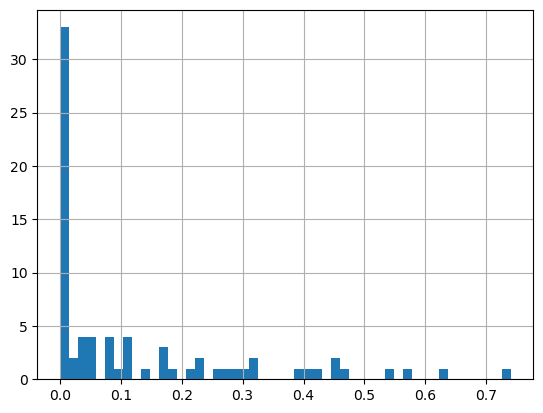

In [138]:
tumor_variant_summary[tumor_variant_summary["total_count"] > 20]["variant_frequency"].hist(bins=50) 

<Axes: >

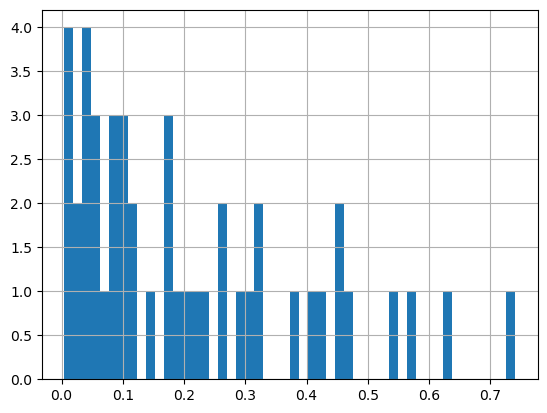

In [139]:
tumor_variant_summary[(tumor_variant_summary["variant_frequency"]!=0) & (tumor_variant_summary["total_count"] > 20)]["variant_frequency"].hist(bins=50)

In [140]:
tumor_clones = [ t for t in A_dict.keys() if t != normal_A ]

In [141]:
t = tumor_clones[0]

/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_7975/976218761.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vaf_list, labels=tumor_clones)


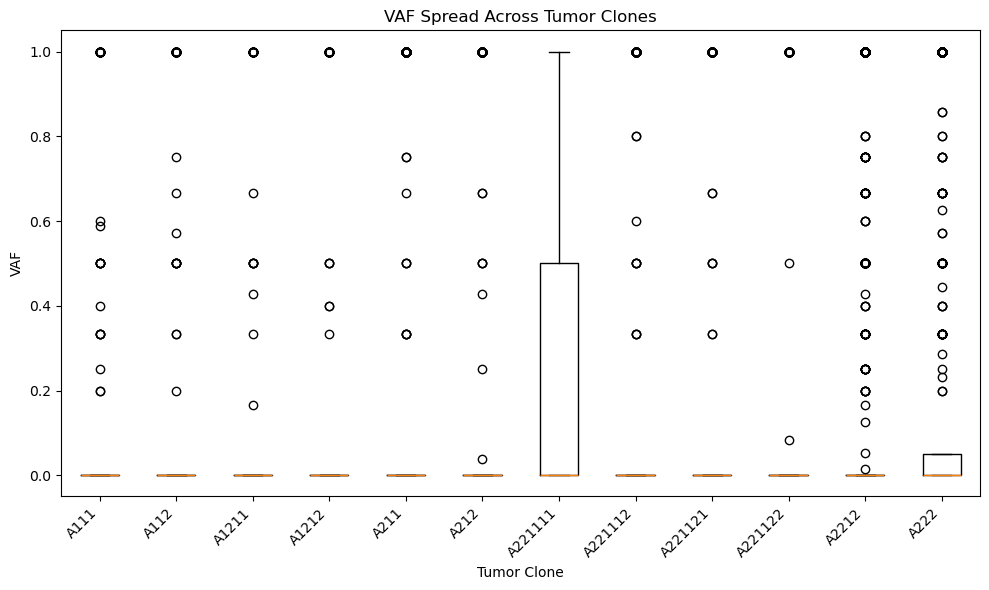

In [142]:
vaf_list = []
vaf_dict = {}

# Need to redefine pos_groups for tumor cells only
tumor_info = tumor_variants_real[~tumor_variants_real["cell_id"].isin(A_dict[normal_A]["cells"])]
pos_groups = tumor_info.groupby(["chrom", "pos"])

for t in tumor_clones:
    # Get variant data for this tumor clone
    tumor_clone_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[t]["cells"])]
    unique_positions = tumor_clone_info[["chrom", "pos"]].drop_duplicates().values.tolist()
    
    vaf_spread = []
    for p in unique_positions:
        try:
            # Get all observations of this variant position across cells in this clone
            df = tumor_clone_info[(tumor_clone_info["chrom"] == p[0]) & (tumor_clone_info["pos"] == p[1])]
            r_count = df["ref_count"].sum()
            a_count = df["alt_count"].sum()
            tot = r_count + a_count
            if tot > 0:  # Avoid division by zero
                vaf = a_count / tot
                vaf_spread.append(vaf)
        except:
            continue
    
    vaf_dict[t] = vaf_spread
    vaf_list.append(vaf_spread)  # This should be OUTSIDE the position loop

# Now plot
plt.figure(figsize=(10, 6))
plt.boxplot(vaf_list, labels=tumor_clones)
plt.ylabel("VAF")
plt.xlabel("Tumor Clone")
plt.title("VAF Spread Across Tumor Clones")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()